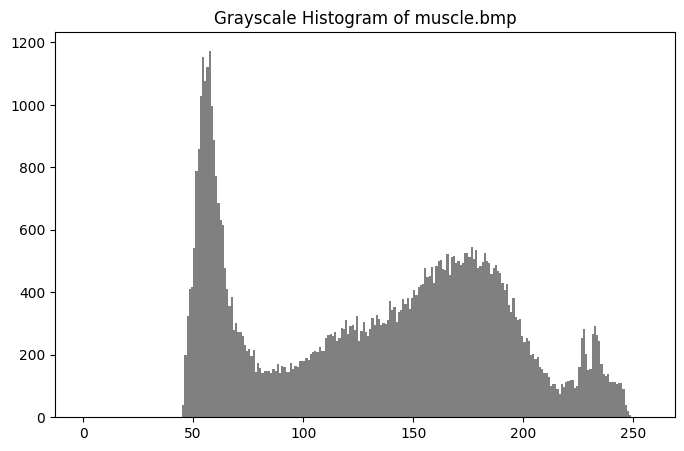

In [10]:
import cv2
import matplotlib.pyplot as plt


path = r'C:\Users\pc\Documents\TP4_image\muscle.bmp' 

img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)

if img is None:
    print("STILL NOT FOUND. Please check:")
    print("1. Is the file really named muscle.bmp? (Check if it's .jpg or .png)")
    print(f"2. Does this path exist? {path}")
else:
    plt.figure(figsize=(8, 5))
    plt.hist(img.ravel(), bins=256, range=[0, 256], color='gray')
    plt.title('Grayscale Histogram of muscle.bmp')
    plt.show()

In [30]:
T = 125 

_, segmented_img = cv2.threshold(img, T, 255, cv2.THRESH_BINARY)

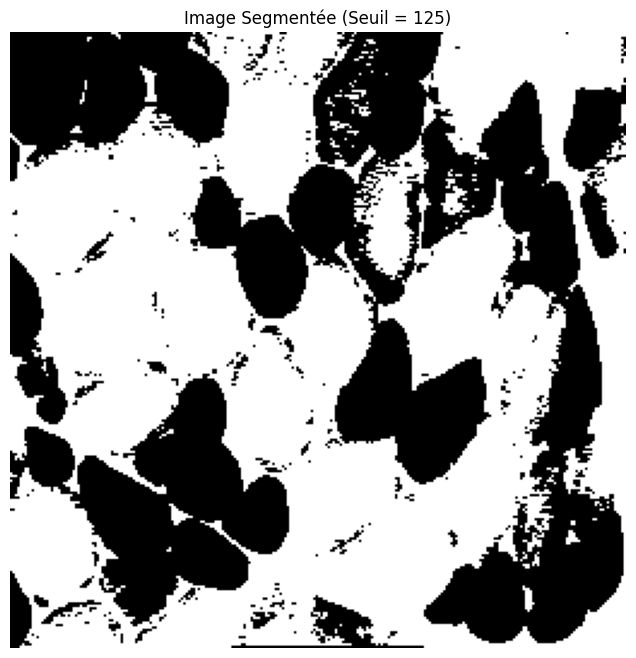

In [32]:
# Affichage
plt.figure(figsize=(8, 8))
plt.imshow(segmented_img, cmap='gray') # Important : cmap='gray' pour le noir et blanc
plt.title(f'Image Segmentée (Seuil = 125)')
plt.axis('off') # Pour masquer les axes x et y
plt.show()

Gaussian 1 -> A: 1174.0, m: 57, sigma: 5.95


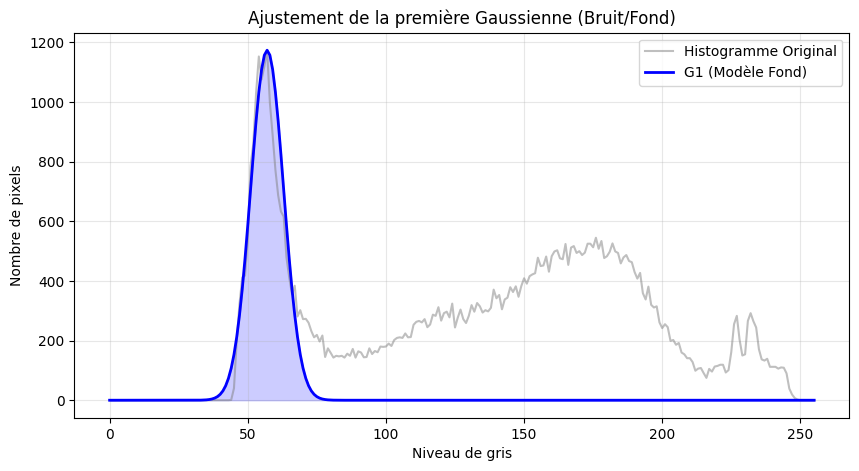

In [54]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import math

# Charger l'image
img = cv2.imread(r'C:\Users\pc\Documents\TP4_image\muscle.bmp' , cv2.IMREAD_GRAYSCALE)

if img is None:
    print("Erreur : Impossible de charger 'muscle.bmp'. Vérifiez le chemin du fichier.")
else:
    hist = cv2.calcHist([img], [0], None, [256], [0, 256]).flatten()

    # 2.2) Fonction pour calculer les paramètres Gaussiens
    def calc_gaussian_params(h):
        A = np.max(h)
        m = np.argmax(h)
        
        # Recherche de l'index à mi-hauteur (vers la gauche)
        index_half_nv = m
        half_A = A / 2
        for i in range(m, -1, -1):
            if h[i] <= half_A:
                index_half_nv = i
                break
        
        # Calcul de sigma : (m - index_half_nv) / sqrt(2 * log(2))
        # On utilise abs() pour éviter les problèmes si index_half_nv est à droite
        sigma = abs(m - index_half_nv) / math.sqrt(2 * math.log(2))
        if sigma == 0: sigma = 1.0 # Sécurité
        
        return A, m, sigma

    # 2.3) Calcul pour la première gaussienne
    A1, m1, sigma1 = calc_gaussian_params(hist)
    print(f"Gaussian 1 -> A: {A1}, m: {m1}, sigma: {sigma1:.2f}")

    # 2.4) Calcul de la courbe G1 sur tout l'axe [0-255]
    nv = np.arange(256)
    # CORRECTION ICI : Utilisation de **2 pour la puissance
    G1 = A1 * np.exp(-((nv - m1)**2) / (2 * (sigma1**2)))

    # Visualisation
    plt.figure(figsize=(10, 5))
    plt.plot(nv, hist, label='Histogramme Original', color='gray', alpha=0.5)
    plt.plot(nv, G1, label='G1 (Modèle Fond)', color='blue', linewidth=2)
    plt.fill_between(nv, G1, color='blue', alpha=0.2) # Optionnel: remplit la courbe
    plt.title('Ajustement de la première Gaussienne (Bruit/Fond)')
    plt.xlabel('Niveau de gris')
    plt.ylabel('Nombre de pixels')
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()

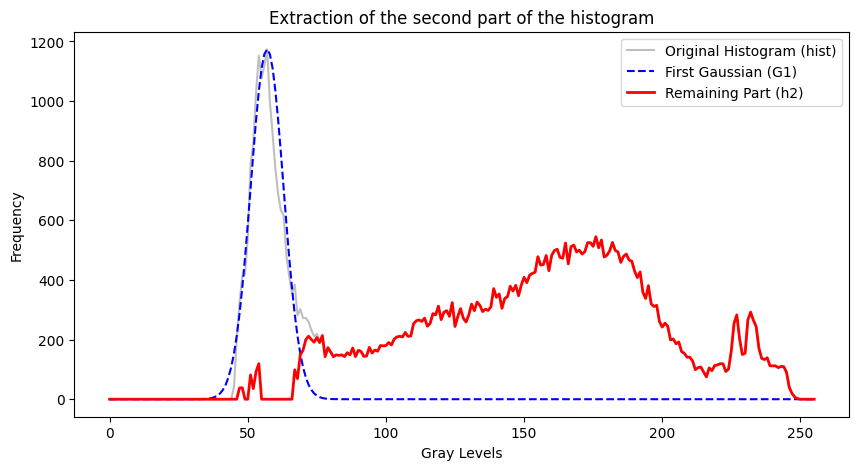

In [56]:
# 2.6) Extract the second part (h2) of the histogram
# We subtract the first Gaussian model from the original histogram
h2 = hist - G1

# Important: After subtraction, some values might become negative 
# (if G1 is slightly higher than the actual histogram). 
# We set those negative values to zero.
h2[h2 < 0] = 0

# Visualization to see the result of the extraction
plt.figure(figsize=(10, 5))
plt.plot(nv, hist, label='Original Histogram (hist)', color='gray', alpha=0.5)
plt.plot(nv, G1, label='First Gaussian (G1)', color='blue', linestyle='--')
plt.plot(nv, h2, label='Remaining Part (h2)', color='red', linewidth=2)

plt.title('Extraction of the second part of the histogram')
plt.xlabel('Gray Levels')
plt.ylabel('Frequency')
plt.legend()
plt.show()

Gaussian 2 (Cells) -> A: 545.0, m: 176, sigma: 39.92


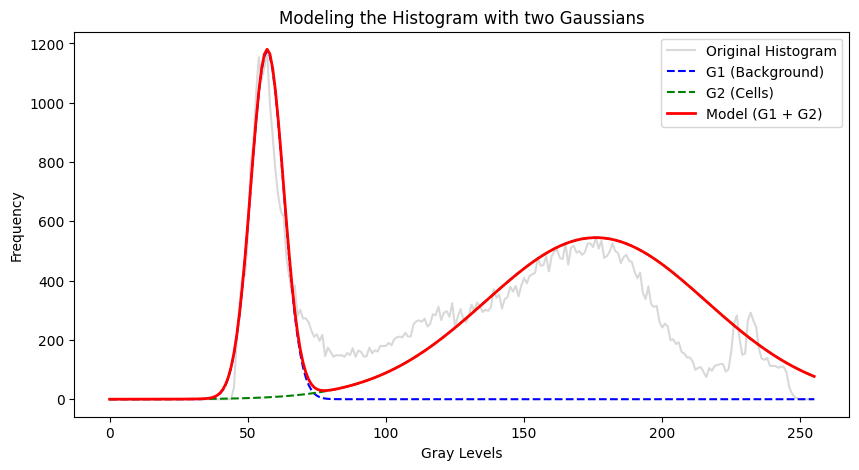

In [58]:
# 2.7) Determine the characteristics of the Gaussian associated with h2
# We apply the same function to the 'h2' portion we extracted
A2, m2, sigma2 = calc_gaussian_params(h2)

print(f"Gaussian 2 (Cells) -> A: {A2}, m: {m2}, sigma: {sigma2:.2f}")

# Compute the G2 curve for all gray levels [0 255]
# Formula: G2(nv) = A2 * exp(-(nv-m2)^2 / (2*sigma2^2))
G2 = A2 * np.exp(-((nv - m2)**2) / (2 * (sigma2**2)))

# --- Visualization for verification ---
plt.figure(figsize=(10, 5))
plt.plot(nv, hist, label='Original Histogram', color='gray', alpha=0.3)
plt.plot(nv, G1, label='G1 (Background)', color='blue', linestyle='--')
plt.plot(nv, G2, label='G2 (Cells)', color='green', linestyle='--')
plt.plot(nv, G1 + G2, label='Model (G1 + G2)', color='red', linewidth=2)

plt.title('Modeling the Histogram with two Gaussians')
plt.xlabel('Gray Levels')
plt.ylabel('Frequency')
plt.legend()
plt.show()

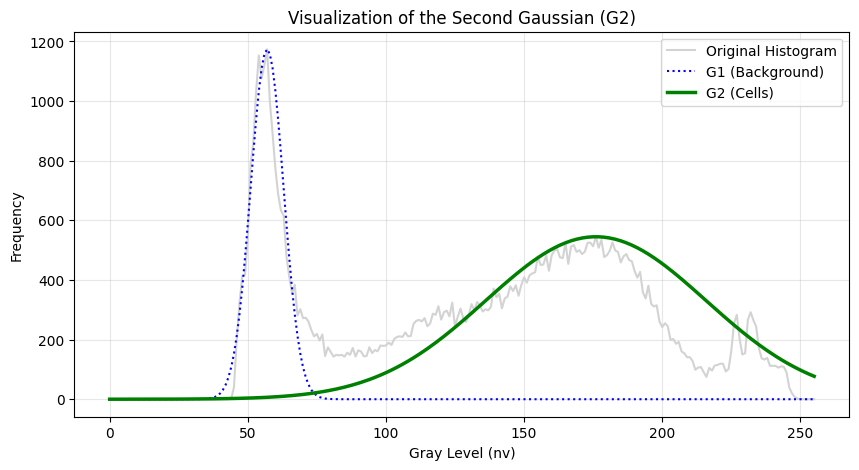

In [60]:
# 1. Define the range of gray levels (nv) from 0 to 255
nv = np.arange(256)

# 2. Compute the Gaussian curve G2 using the formula provided
# Note: Ensure you use **2 for squaring in Python
G2 = A2 * np.exp(-((nv - m2)**2) / (2 * (sigma2**2)))

# 3. Visualization
plt.figure(figsize=(10, 5))

# Plot the original histogram as a background reference
plt.plot(nv, hist, label='Original Histogram', color='lightgray')

# Plot the first Gaussian G1 (calculated earlier)
plt.plot(nv, G1, label='G1 (Background)', color='blue', linestyle=':')

# Plot the second Gaussian G2 (The focus of this question)
plt.plot(nv, G2, label='G2 (Cells)', color='green', linewidth=2.5)

plt.title('Visualization of the Second Gaussian (G2)')
plt.xlabel('Gray Level (nv)')
plt.ylabel('Frequency')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

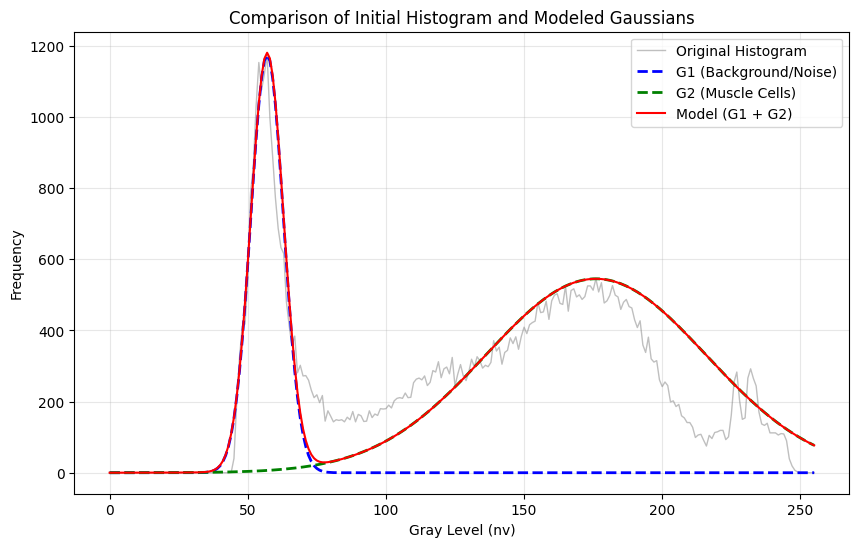

In [62]:
plt.figure(figsize=(10, 6))

# Plot the original histogram
plt.plot(nv, hist, label='Original Histogram', color='gray', alpha=0.5, linewidth=1)

# Plot the first Gaussian (G1)
plt.plot(nv, G1, label='G1 (Background/Noise)', color='blue', linestyle='--', linewidth=2)

# Plot the second Gaussian (G2)
plt.plot(nv, G2, label='G2 (Muscle Cells)', color='green', linestyle='--', linewidth=2)

# Plot the sum of both Gaussians (to show the combined model)
plt.plot(nv, G1 + G2, label='Model (G1 + G2)', color='red', linewidth=1.5)

plt.title('Comparison of Initial Histogram and Modeled Gaussians')
plt.xlabel('Gray Level (nv)')
plt.ylabel('Frequency')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [68]:
import numpy as np
import math

def Gaussian_thresholding(h):
  
    # --- Helper: Parameter Estimation (Inside to keep function standalone) ---
    def get_params(hist_data):
        A = np.max(hist_data)
        m = np.argmax(hist_data)
        
        # Find index_half_nv (searching left from the peak)
        half_A = A / 2
        index_half_nv = m
        for i in range(m, -1, -1):
            if hist_data[i] <= half_A:
                index_half_nv = i
                break
        
        sigma = abs(m - index_half_nv) / math.sqrt(2 * math.log(2))
        if sigma == 0: sigma = 1.0  # Prevent division by zero
        return A, m, sigma

    nv = np.arange(256)

    # 1. Estimate parameters and model for G1 (Background)
    A1, m1, sigma1 = get_params(h)
    G1 = A1 * np.exp(-((nv - m1)**2) / (2 * (sigma1**2)))

    # 2. Extract h2 and estimate parameters and model for G2 (Cells)
    h2 = h - G1
    h2[h2 < 0] = 0  # Remove negative values
    A2, m2, sigma2 = get_params(h2)
    G2 = A2 * np.exp(-((nv - m2)**2) / (2 * (sigma2**2)))

    # 3. Find the intersection between the two peaks (m1 and m2)
    # We search the range between the two means
    start = int(min(m1, m2))
    end = int(max(m1, m2))
    
    search_range = np.arange(start, end)
    
    # Calculate the absolute difference between the two Gaussians in the search range
    differences = np.abs(G1[search_range] - G2[search_range])
    
    # The optimal threshold is the gray level where the difference is minimal
    idx_min = np.argmin(differences)
    T_optimal = search_range[idx_min]

    return T_optimal



Optimal automatic threshold calculated: T = 74


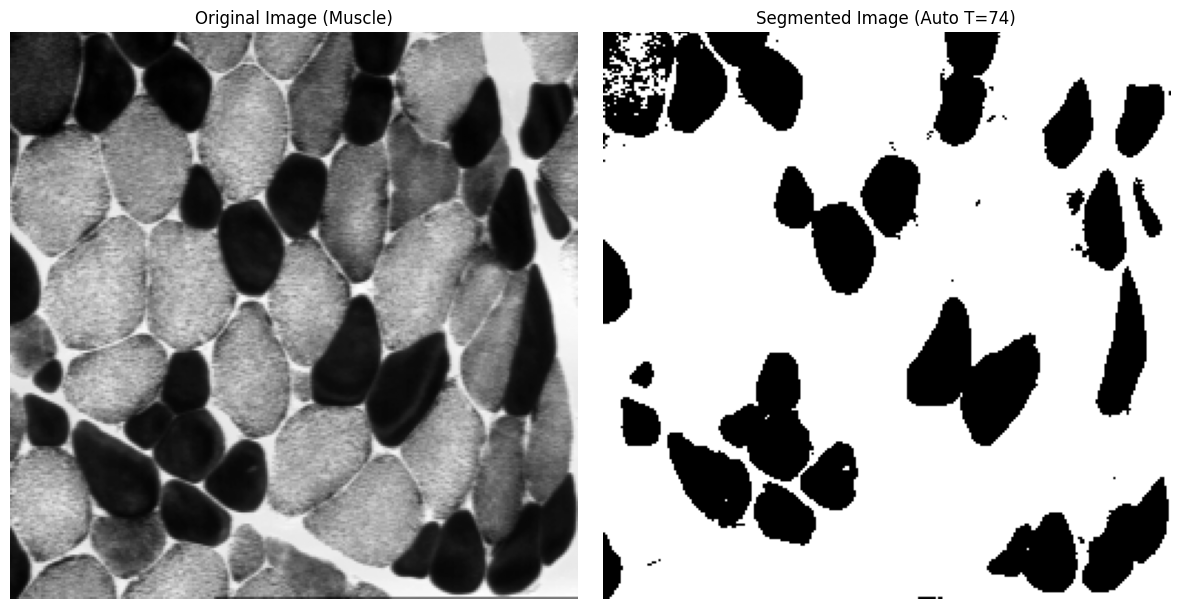

In [70]:
# 1. Calculate the optimal threshold using your automatic function
T_auto = Gaussian_thresholding(hist)
print(f"Optimal automatic threshold calculated: T = {T_auto}")

# 2. Apply the thresholding to the image
# Any pixel > T_auto becomes 255 (white), others become 0 (black)
_, img_segmented = cv2.threshold(img, T_auto, 255, cv2.THRESH_BINARY)

# 3. Visualization
plt.figure(figsize=(12, 6))

# Display Original Image
plt.subplot(1, 2, 1)
plt.imshow(img, cmap='gray')
plt.title('Original Image (Muscle)')
plt.axis('off')

# Display Segmented Image
plt.subplot(1, 2, 2)
plt.imshow(img_segmented, cmap='gray')
plt.title(f'Segmented Image (Auto T={T_auto})')
plt.axis('off')

plt.tight_layout()
plt.show()

Image Shape: (400, 600, 3)


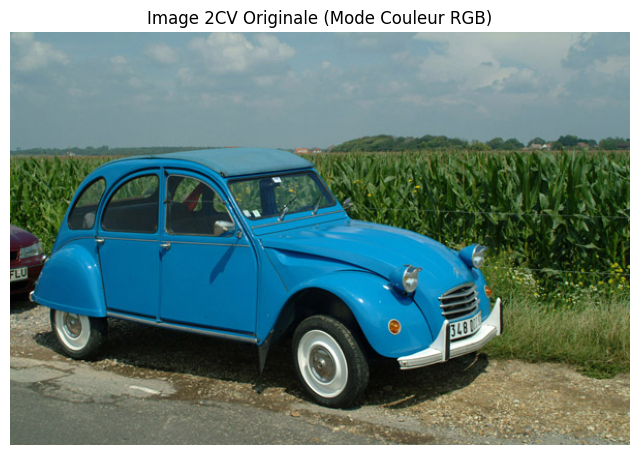

In [84]:
import cv2
import matplotlib.pyplot as plt

# Charger l'image (déjà fait dans votre code, mais on s'assure qu'elle existe)
img_2cv = cv2.imread('2CV.tif')

if img_2cv is not None:
    # 1. Convertir l'image de BGR (OpenCV) à RGB (Matplotlib)
    img_rgb = cv2.cvtColor(img_2cv, cv2.COLOR_BGR2RGB)
    print(f"Image Shape: {img_2cv.shape}")
    # 2. Affichage
    plt.figure(figsize=(8, 6))
    plt.imshow(img_rgb)
    plt.title('Image 2CV Originale (Mode Couleur RGB)')
    plt.axis('off') # Pour enlever les graduations x et y
    plt.show()
else:
    print("L'image n'a pas pu être chargée.")

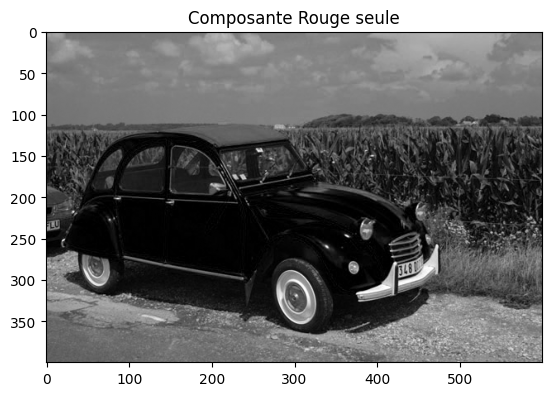

In [80]:
plt.imshow(img_2cv[:,:,2], cmap='gray') 
plt.title('Composante Rouge seule')
plt.show()

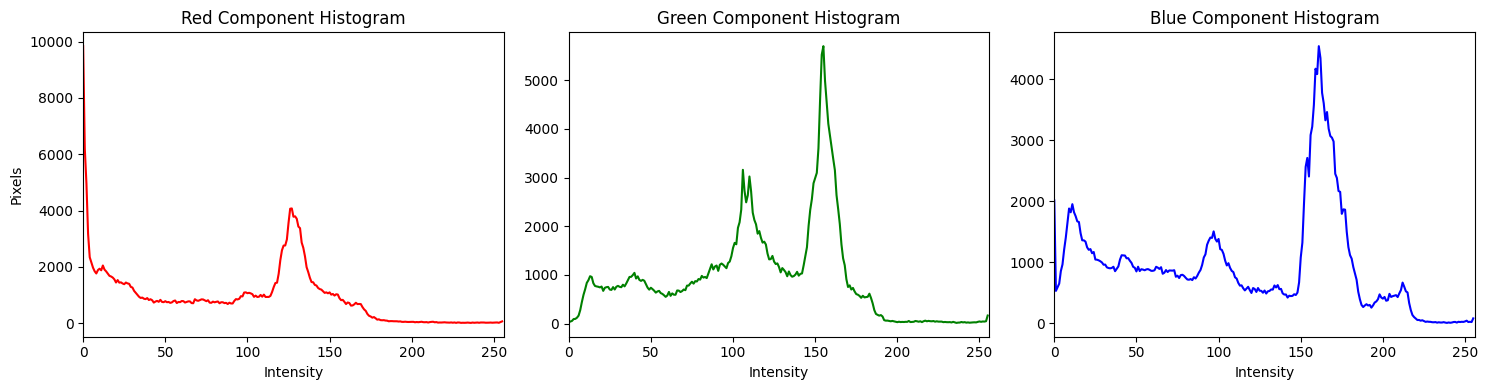

In [76]:
# 1. Split the image into Blue, Green, and Red channels
b_chan, g_chan, r_chan = cv2.split(img_2cv)

# 2. Compute histograms for each channel
hist_r = cv2.calcHist([r_chan], [0], None, [256], [0, 256])
hist_g = cv2.calcHist([g_chan], [0], None, [256], [0, 256])
hist_b = cv2.calcHist([b_chan], [0], None, [256], [0, 256])

# 3. Visualization side-by-side
plt.figure(figsize=(15, 4))

# Red Histogram
plt.subplot(1, 3, 1)
plt.plot(hist_r, color='red')
plt.title('Red Component Histogram')
plt.xlabel('Intensity')
plt.ylabel('Pixels')
plt.xlim([0, 256])

# Green Histogram
plt.subplot(1, 3, 2)
plt.plot(hist_g, color='green')
plt.title('Green Component Histogram')
plt.xlabel('Intensity')
plt.xlim([0, 256])

# Blue Histogram
plt.subplot(1, 3, 3)
plt.plot(hist_b, color='blue')
plt.title('Blue Component Histogram')
plt.xlabel('Intensity')
plt.xlim([0, 256])

plt.tight_layout()
plt.show()

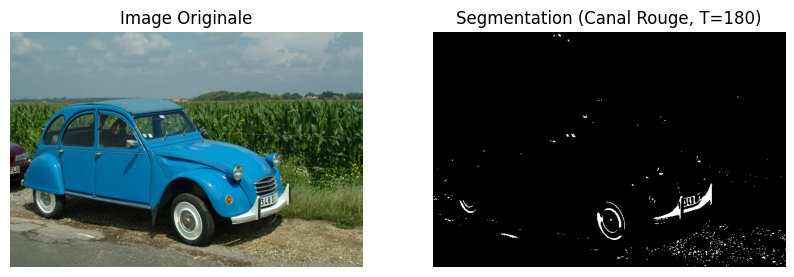

In [86]:
# 1. Extraction de la composante Rouge
# Rappel : OpenCV charge en BGR, donc l'indice 2 est le Rouge
r_chan = img_2cv[:, :, 2]

# 2. Choix d'un seuil visuel (basé sur l'histogramme rouge)
# Si le pic de la voiture est à droite, on prend une valeur juste avant ce pic
T_rouge = 180 

# 3. Seuillage binaire
_, car_segmented = cv2.threshold(r_chan, T_rouge, 255, cv2.THRESH_BINARY)

# 4. Visualisation
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(img_2cv, cv2.COLOR_BGR2RGB))
plt.title('Image Originale')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(car_segmented, cmap='gray')
plt.title(f'Segmentation (Canal Rouge, T={T_rouge})')
plt.axis('off')

plt.show()

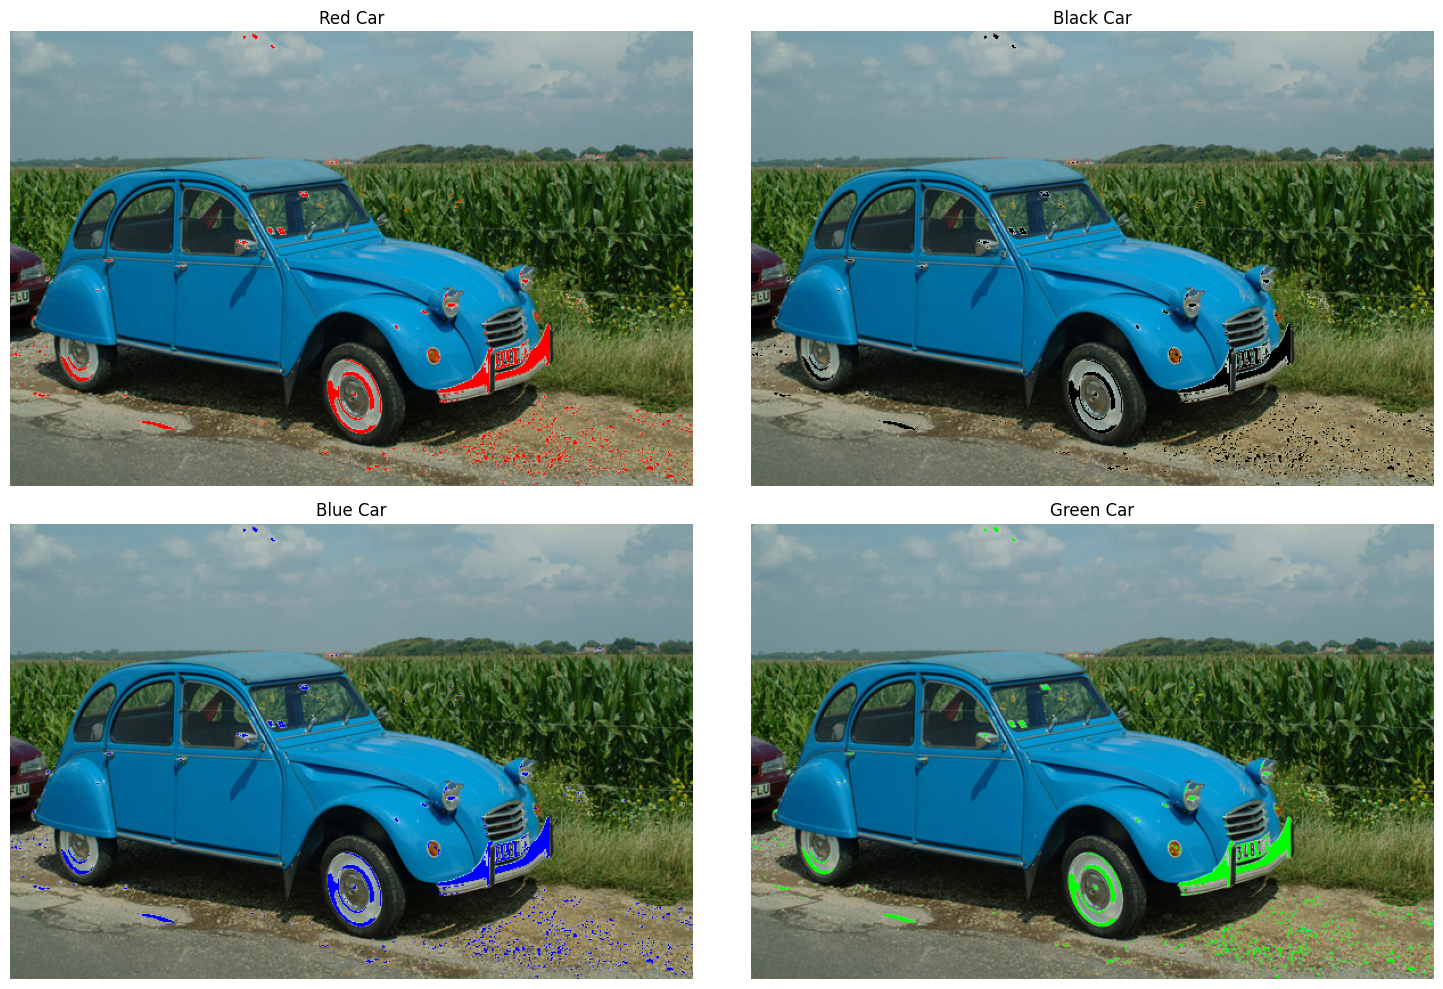

In [90]:
# Create copies of the original BGR image for each color
img_red   = img_2cv.copy()
img_black = img_2cv.copy()
img_blue  = img_2cv.copy()
img_green = img_2cv.copy()

# Apply colors where the mask is 255 (White)
# Reminder: OpenCV uses BGR order [Blue, Green, Red]

# 1. Red (B=0, G=0, R=255)
img_red[car_segmented == 255] = [0, 0, 255]

# 2. Black (B=0, G=0, R=0)
img_black[car_segmented == 255] = [0, 0, 0]

# 3. Blue (B=255, G=0, R=0)
img_blue[car_segmented == 255] = [255, 0, 0]

# 4. Green (B=0, G=255, R=0)
img_green[car_segmented == 255] = [0, 255, 0]

# Visualization
plt.figure(figsize=(15, 10))
titles = ['Red Car', 'Black Car', 'Blue Car', 'Green Car']
images = [img_red, img_black, img_blue, img_green]

for i in range(4):
    plt.subplot(2, 2, i+1)
    # Convert BGR to RGB for matplotlib
    plt.imshow(cv2.cvtColor(images[i], cv2.COLOR_BGR2RGB))
    plt.title(titles[i])
    plt.axis('off')

plt.tight_layout()
plt.show()

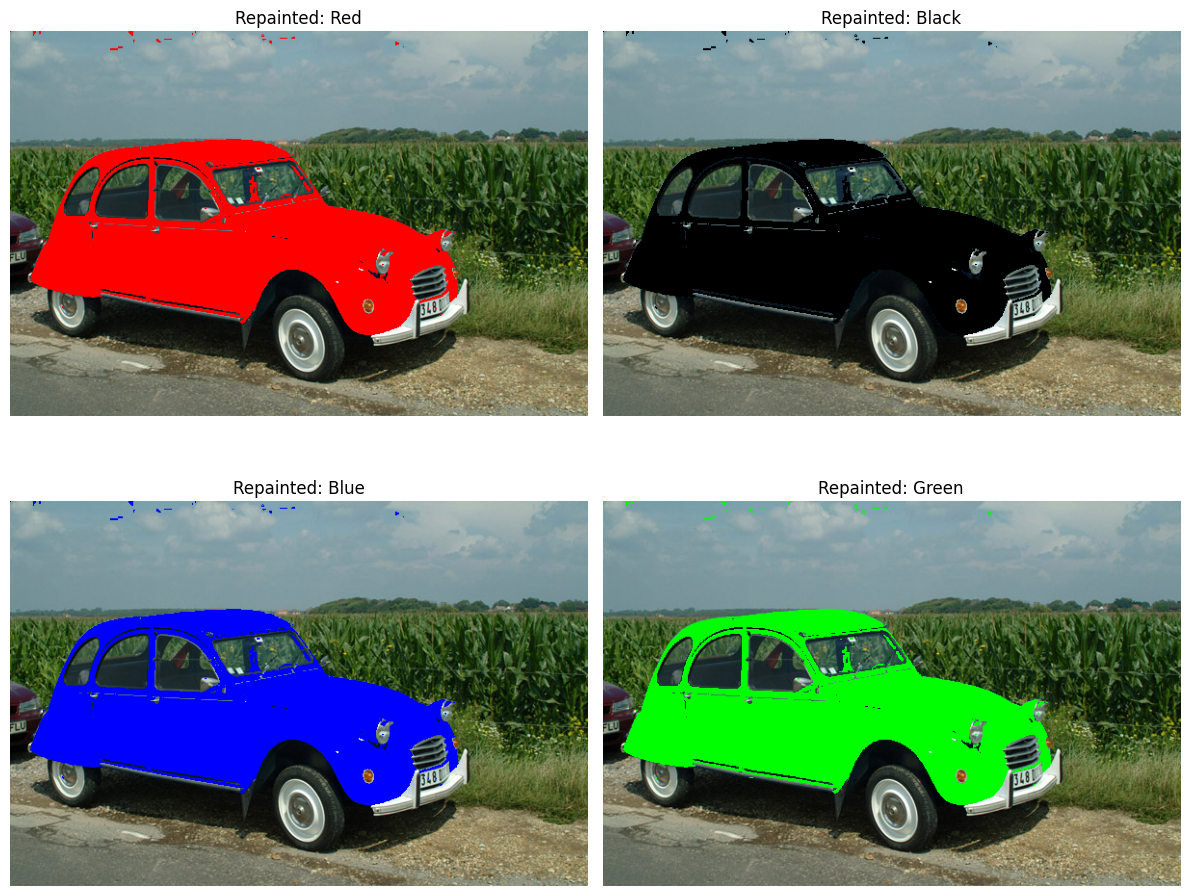

In [100]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# On s'assure que img_2cv existe (le nom que vous avez utilisé au début)
if 'img_2cv' not in locals():
    img_2cv = cv2.imread('2CV.tif')

# --- Calcul du masque (version améliorée pour cibler la carrosserie bleue) ---
# On utilise img_2cv ici
blue_channel = img_2cv[:, :, 0]
red_channel = img_2cv[:, :, 2]
blue_minus_red = cv2.subtract(blue_channel, red_channel)
_, final_car_mask = cv2.threshold(blue_minus_red, 50, 255, cv2.THRESH_BINARY)
# --------------------------------------------------------------------

# Couleurs cibles en format BGR
colors = {
    'Red': (0, 0, 255),
    'Black': (0, 0, 0),
    'Blue': (255, 0, 0),    
    'Green': (0, 255, 0)
}

plt.figure(figsize=(12, 10))

for i, (color_name, bgr_value) in enumerate(colors.items(), 1):
    # 1. On utilise img_2cv pour la copie
    recolored_img = img_2cv.copy()
    
    # 2. On applique la couleur sur le masque
    recolored_img[final_car_mask > 0] = bgr_value
    
    # 3. Conversion BGR vers RGB pour l'affichage Matplotlib
    recolored_img_rgb = cv2.cvtColor(recolored_img, cv2.COLOR_BGR2RGB)
    
    plt.subplot(2, 2, i)
    plt.imshow(recolored_img_rgb)
    plt.title(f'Repainted: {color_name}')
    plt.axis('off')

plt.tight_layout()
plt.show()